## EDA Time-Series

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv", parse_dates=["date"])

print(df.shape)
print(df["date"].min(), "sampai", df["date"].max())
print(f"Jumlah toko: {df['store'].nunique()}, jumlah produk: {df['item'].nunique()}")
df.head()

(913000, 4)
2013-01-01 00:00:00 sampai 2017-12-31 00:00:00
Jumlah toko: 10, jumlah produk: 50


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### Pola musiman & tren keseluruhan

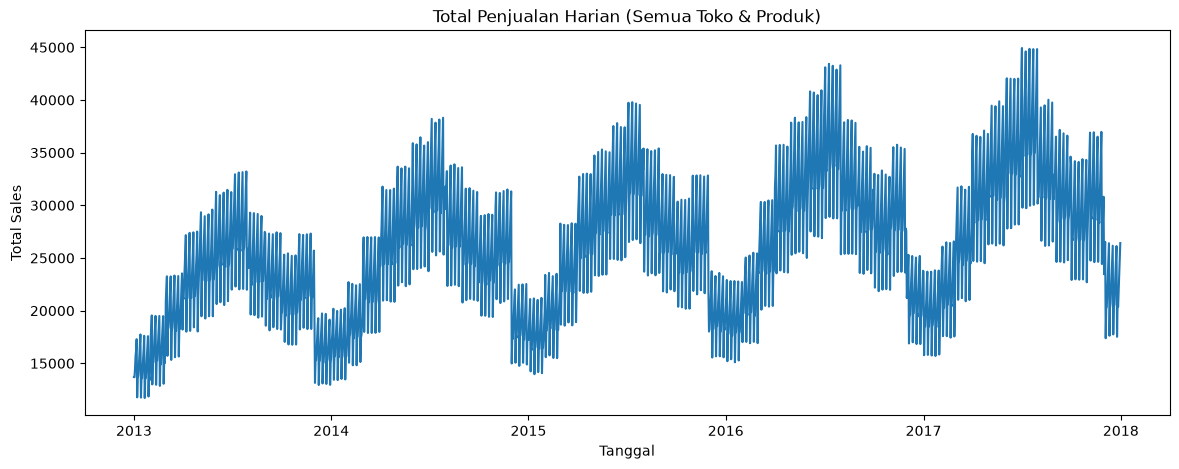

In [2]:
import matplotlib.pyplot as plt

daily_total = df.groupby("date")["sales"].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_total["date"], daily_total["sales"])
plt.title("Total Penjualan Harian (Semua Toko & Produk)")
plt.xlabel("Tanggal")
plt.ylabel("Total Sales")
plt.savefig("../reports/daily_sales_trend.png", dpi=150)
plt.show()

### Pola mingguan

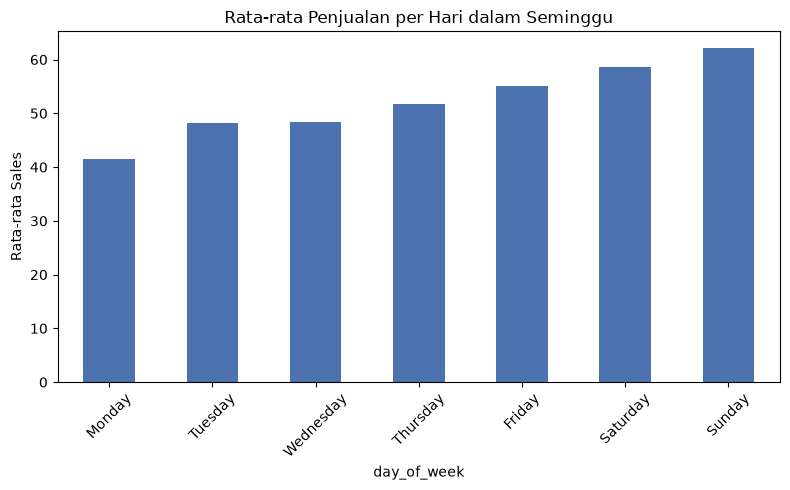

In [3]:
df["day_of_week"] = df["date"].dt.day_name()
weekly_pattern = df.groupby("day_of_week")["sales"].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
)

plt.figure(figsize=(8, 5))
weekly_pattern.plot(kind="bar", color="#4C72B0")
plt.title("Rata-rata Penjualan per Hari dalam Seminggu")
plt.ylabel("Rata-rata Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/weekly_pattern.png", dpi=150)
plt.show()

### Variasi antar toko dan antar produk

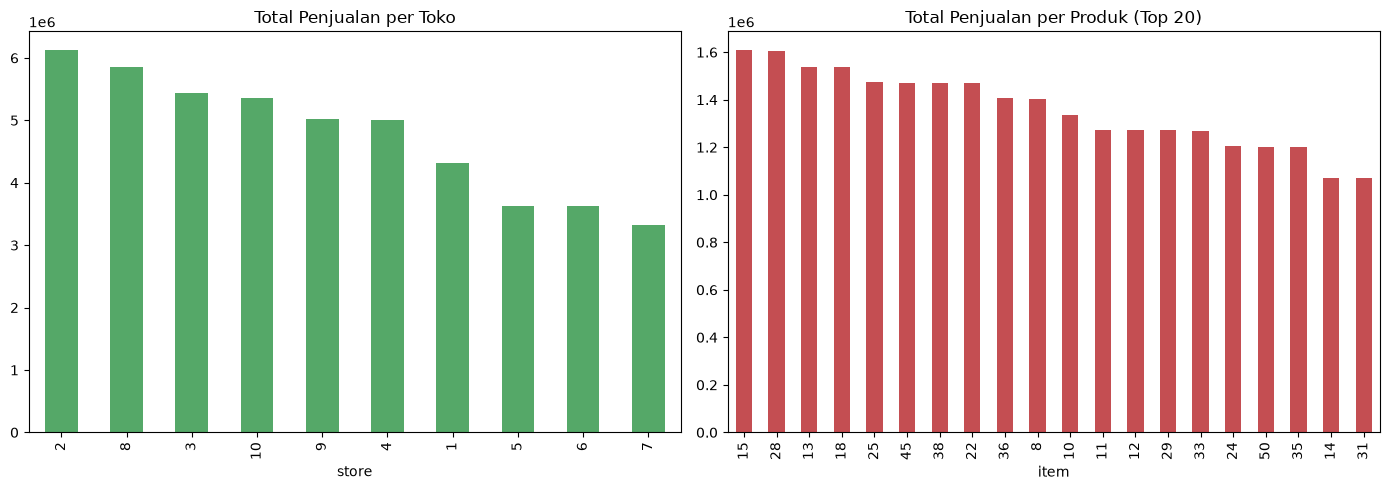

In [4]:
store_totals = df.groupby("store")["sales"].sum().sort_values(ascending=False)
item_totals = df.groupby("item")["sales"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
store_totals.plot(kind="bar", ax=axes[0], color="#55A868")
axes[0].set_title("Total Penjualan per Toko")
item_totals.head(20).plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Total Penjualan per Produk (Top 20)")
plt.tight_layout()
plt.savefig("../reports/store_item_variation.png", dpi=150)
plt.show()

### Cek kelengkapan data atau null

In [5]:
expected_days = (df["date"].max() - df["date"].min()).days + 1
actual_days_per_combo = df.groupby(["store", "item"])["date"].nunique()

print(f"Jumlah hari seharusnya: {expected_days}")
print(f"Kombinasi toko-produk dengan data tidak lengkap: {(actual_days_per_combo != expected_days).sum()}")

Jumlah hari seharusnya: 1826
Kombinasi toko-produk dengan data tidak lengkap: 0


## Baseline Forecasting
Tes ke satu kombinasi toko-produk dulu untuk eksplorasi baseline

In [7]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

sample = df[(df["store"] == 1) & (df["item"] == 1)].sort_values("date").reset_index(drop=True)
sample = sample.set_index("date")["sales"]

# Baseline 1: Naive (prediksi = nilai hari sebelumnya)
naive_pred = sample.shift(1)

# Baseline 2: Moving average 7 hari
ma7_pred = sample.rolling(window=7).mean().shift(1)

# Baseline 3: Exponential smoothing sederhana
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(
    sample.dropna(),
    initialization_method="estimated"
).fit(smoothing_level=0.3, optimized=False)
ses_pred = ses_model.fittedvalues

d:\Albert\Proyek\retail-demand-forecasting\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


### Evaluasi baseline dengan MAE dan RMSE

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_baseline(y_true, y_pred, name):
    mask = ~y_pred.isna()
    mae = mean_absolute_error(y_true[mask], y_pred[mask])
    rmse = np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
    print(f"{name}: MAE={mae:.2f}, RMSE={rmse:.2f}")
    return mae, rmse

evaluate_baseline(sample, naive_pred, "Naive")
evaluate_baseline(sample, ma7_pred, "Moving Average 7-hari")
evaluate_baseline(sample, ses_pred, "Exponential Smoothing")

Naive: MAE=5.51, RMSE=7.08
Moving Average 7-hari: MAE=4.28, RMSE=5.44
Exponential Smoothing: MAE=4.45, RMSE=5.67


(4.445642261257686, np.float64(5.6707824912441716))

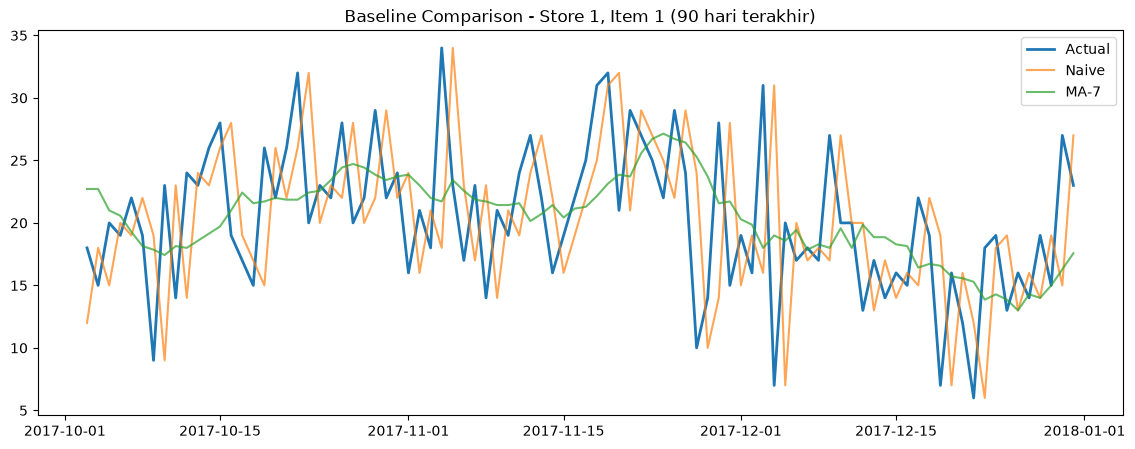

In [9]:
plt.figure(figsize=(14, 5))
plt.plot(sample.index[-90:], sample.values[-90:], label="Actual", linewidth=2)
plt.plot(naive_pred.index[-90:], naive_pred.values[-90:], label="Naive", alpha=0.7)
plt.plot(ma7_pred.index[-90:], ma7_pred.values[-90:], label="MA-7", alpha=0.7)
plt.legend()
plt.title("Baseline Comparison - Store 1, Item 1 (90 hari terakhir)")
plt.savefig("../reports/baseline_comparison.png", dpi=150)
plt.show()

## Fitur Lag & Rolling Window
Fitur untuk seluruh kombinasi toko-produk sekaligus

In [10]:
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)

# Fitur kalender
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

# Fitur lag -- PENTING: groupby(["store","item"]) supaya lag tidak "bocor" antar kombinasi berbeda
group_cols = ["store", "item"]
for lag in [1, 7, 14, 28]:
    df[f"sales_lag_{lag}"] = df.groupby(group_cols)["sales"].shift(lag)

# Fitur rolling window -- dihitung dari data yang sudah di-shift supaya tidak bocor ke hari ini
for window in [7, 14, 30]:
    df[f"sales_roll_mean_{window}"] = (
        df.groupby(group_cols)["sales"].shift(1).rolling(window).mean()
    )
    df[f"sales_roll_std_{window}"] = (
        df.groupby(group_cols)["sales"].shift(1).rolling(window).std()
    )

print(f"Shape setelah feature engineering: {df.shape}")
print(f"Baris dengan NaN (karena lag/rolling di awal data): {df.isnull().any(axis=1).sum()}")

Shape setelah feature engineering: (913000, 20)
Baris dengan NaN (karena lag/rolling di awal data): 15000


In [11]:
# Baris dengan NaN di awal (karena belum ada cukup histori untuk lag 28 hari) harus dibuang
df_model = df.dropna().reset_index(drop=True)
print(f"Shape setelah drop NaN: {df_model.shape}")

df_model.to_parquet(PROJECT_ROOT / "data" / "processed" / "sales_features.parquet", index=False)

Shape setelah drop NaN: (898000, 20)
